# Frank–Wolfe Optimization on the Probability Simplex

Solve a strictly convex quadratic over the three-dimensional probability simplex using conditional gradient (Frank–Wolfe) with an exact line search and a duality-gap stopping rule.

[Technical notes](../docs/frank_wolfe.md) · [Saved figures](../results/frank_wolfe/)

In [6]:
import numpy as np
import matplotlib.pyplot as plt

## Quadratic objective and simplex oracle

$$\min_{x\ge0,\,\mathbf1^Tx=1}\; \tfrac12(x_1^2+x_2^2+0.1x_3^2)+0.55x_3.$$

The gradient is $(x_1,x_2,0.1x_3+0.55)^T$. The linear minimization oracle returns the unit vector at the index with the smallest gradient component. For $d=s-x$, exact line search gives $\alpha=\operatorname{clip}(-g^Td/(d^TQd),0,1)$ with $Q=\operatorname{diag}(1,1,0.1)$.

In [7]:
def f(x):
    x = np.asarray(x, dtype=float)
    return 0.5*(x[0]**2 + x[1]**2 + 0.1*x[2]**2) + 0.55*x[2]

def grad_f(x):
    x = np.asarray(x, dtype=float)
    return np.array([x[0], x[1], 0.1*x[2] + 0.55])

def linear_oracle_simplex(g):
    s = np.zeros_like(g)
    s[np.argmin(g)] = 1.0
    return s

def exact_line_search(x, d):
    g = grad_f(x)
    denom = d[0]**2 + d[1]**2 + 0.1*d[2]**2
    num = -np.dot(g, d)

    if denom <= 0:
        return 1.0 if num > 0 else 0.0

    return float(np.clip(num / denom, 0.0, 1.0))


## Frank–Wolfe iteration

Update $x_{k+1}=x_k+\alpha_k(s_k-x_k)$. Convex combinations preserve feasibility; the implementation also performs numerical cleanup. Stop when $g_{FW}=\nabla f(x_k)^T(x_k-s_k)\le10^{-4}$ or the iteration limit is reached.

In [24]:
def frank_wolfe(x0, max_iter=5000, tol_gap=1e-4):
    x = np.asarray(x0, dtype=float)

    if np.any(x < 0) or abs(np.sum(x) - 1.0) > 1e-8:
        raise ValueError("Initial point must be nonnegative and sum to 1.")

    f_values = []
    gaps = []

    for k in range(max_iter):
        g = grad_f(x)
        s = linear_oracle_simplex(g)
        d = s - x

        gap = np.dot(g, x - s)

        f_values.append(f(x))
        gaps.append(gap)

        if gap <= tol_gap:
            break

        alpha = exact_line_search(x, d)
        x = x + alpha * d

        # numerical cleanup
        x[x < 0] = 0.0
        x = x / np.sum(x)

    # ---- outputs ----
    x_star = x
    final_gap = gaps[-1]
    iters_used = k

    print("x* =", x_star)
    print("final_gap =", final_gap)
    print("iterations =", iters_used)

    # ---- convergence plot  ----
    plt.figure()
    plt.plot(range(len(f_values)), f_values)
    plt.xlabel("Iteration k")
    plt.ylabel("f(x^k)")
    plt.title("Frank–Wolfe Convergence")
    plt.grid(True)
    plt.show()

    return x_star


## Experiment from the simplex centroid

Start at $(1/3,1/3,1/3)$ with a maximum of 5,000 iterations.

x* = [0.49955592 0.49945592 0.00098817]
final_gap = 9.999857700093272e-05
iterations = 4789


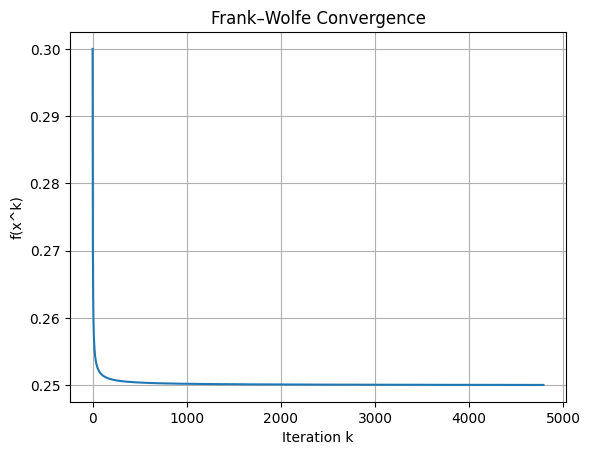

In [25]:
x0 = np.array([1/3, 1/3, 1/3])
x_star = frank_wolfe(x0)

## Results and interpretation

The saved output reports $x=(0.49955592,0.49945592,0.00098817)$, gap $9.999857700093272\times10^{-5}$ and iteration index 4,789. The exact minimizer is $(0.5,0.5,0)$ with objective 0.25: the gradient components for the two positive coordinates are 0.5, while the third is 0.55, satisfying simplex optimality. Strict convexity gives uniqueness.

The convergence curve approaches 0.25 rapidly at first and then slowly. The third coordinate shrinks toward zero; standard Frank–Wolfe steps toward simplex vertices can be slow near a boundary optimum. The nonnegative gap bounds primal suboptimality for this convex problem. The numerical result meets the chosen gap criterion rather than achieving the exact boundary point.